# ML Lab 3 — Decision Tree Classification

## Student Information

- **Name:** Amir khan
- **Student ID:** 023-24-0166
- **Section:** F
- **GitHub Profile:** https://github.com/Amir-Khan11
- **Dataset:** Telco Customer Churn
- **Dataset Source:** Kaggle

# Part 1 — Problem Definition & Dataset Verification


## Task 1 — Dataset Verification


In [ ]:
import pandas as pd

df = pd.read_csv("clean_churn.csv")

In [ ]:
df.shape

(7043, 20)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


### Interpretation

The cleaned dataset contains 7,043 rows and 20 columns, with the expected data types and no missing values remaining. The target variable `Churn` contains 5,174 customers who did not churn and 1,869 customers who churned, confirming that the dataset is ready for further preparation.

## Task 2 — Problem Definition

The goal of this project is to predict whether a customer will churn (leave the company) based on their customer information and service usage. This is important for the business because identifying customers who are likely to churn can help the company take action to retain them and reduce customer loss.

# Part 2 — Feature & Target Preparation

## Task 3 — Define Features and Target

In [ ]:
y = df['Churn'].map({'No': 0, 'Yes': 1})

X = df.drop(columns=['Churn'])

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


### Interpretation

The target variable `y` was successfully separated from the feature variables and encoded as 0 for customers who did not churn and 1 for customers who churned. The feature set `X` contains the remaining 19 columns, while both `X` and `y` contain 7,043 customer records.

## Task 4 — Convert Categorical Features to Numeric

In [ ]:
X = pd.get_dummies(X, dtype=int)

In [ ]:
X.select_dtypes(exclude='number').columns

Index([], dtype='object')

In [ ]:
X.dtypes.value_counts()

,count
int64,43
float64,2


In [ ]:
X.isnull().sum().sum()

np.int64(0)

### Encoding Justification

One-hot encoding was used because the categorical features contain categories without a natural numerical order. It converts these categories into separate binary (0/1) columns, making them suitable as numeric inputs for the Decision Tree model.

### Interpretation

The categorical features were successfully converted into binary numeric columns using one-hot encoding. The resulting feature set contains only numeric data types and has no missing values, so it is ready for the next step.

## Task 5 — Final Feature Verification

In [ ]:
print("Non-numeric columns:")
print(X.select_dtypes(exclude='number').columns)

print("\nTotal missing values:", X.isnull().sum().sum())

Non-numeric columns:
Index([], dtype='object')

Total missing values: 0


### Interpretation

The final verification confirms that `X` contains only numeric columns and has no missing values. Therefore, the feature matrix is fully prepared for use with the Decision Tree model.

# Part 3 — Train/Test Split

## Task 6 — Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

### Why use `stratify=y`?

The `Churn` classes are imbalanced, with 5,174 customers who did not churn and 1,869 who churned. Using `stratify=y` keeps approximately the same class proportions in both the training and test sets, giving a more representative split.

## Task 7 — Training and Test Set Shapes

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 45)
X_test shape: (1409, 45)
y_train shape: (5634,)
y_test shape: (1409,)


### Interpretation

The dataset was split into 5,634 training records and 1,409 test records, with 45 features in both sets. The training data will be used to build the model, while the test data will be kept separate for evaluating its performance on unseen customers.

# Part 4 — Baseline Decision Tree

## Task 8 — Train the Baseline Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("First 10 training predictions:", y_train_pred[:10])
print("First 10 test predictions:", y_test_pred[:10])

First 10 training predictions: [0 0 0 0 0 0 0 0 0 0]
First 10 test predictions: [0 1 0 1 0 0 0 0 0 1]


### Interpretation

The baseline Decision Tree was successfully trained using the training data and generated predictions for both the training and test sets. Only the first 10 predictions are displayed to verify that predictions were produced without printing the entire prediction arrays.

## Task 9 — Baseline Tree Depth

In [ ]:
tree_depth = model.get_depth()

print("Baseline tree depth:", tree_depth)

Baseline tree depth: 23


### Interpretation

The baseline Decision Tree grew to a depth of 23 without setting a maximum depth. This is a relatively deep tree, which is not surprising because the baseline model was unrestricted and allowed to keep splitting the training data using its default settings.

# Part 5 — Model Evaluation

## Task 10 — Test Set Evaluation Metrics

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [ ]:
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.7196593328601846
Precision: 0.4730077120822622
Recall: 0.4919786096256685
F1-score: 0.48230668414154654


In [ ]:
metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [accuracy, precision, recall, f1]
})

metrics

,Metric,Score
0,Accuracy,0.719659
1,Precision,0.473008
2,Recall,0.491979
3,F1-score,0.482307


### Interpretation

The baseline Decision Tree achieved about 72.0% accuracy on the test set. However, its precision, recall, and F1-score are all below 50%, showing that the model has difficulty identifying customers who churn despite having a moderate overall accuracy.

## Task 11 — Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)

print(cm)

[[830 205]
 [190 184]]


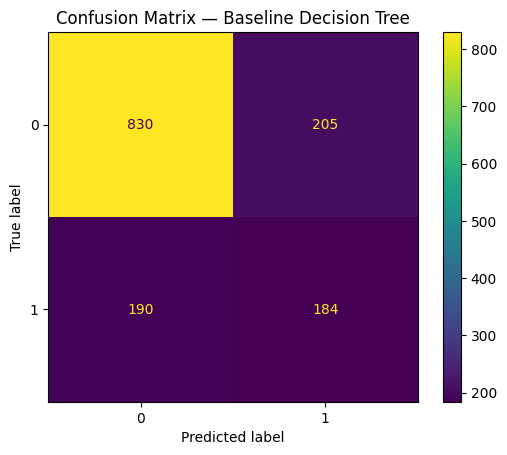

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)

plt.title("Confusion Matrix — Baseline Decision Tree")
plt.show()

### Interpretation

The confusion matrix shows that the model correctly identified 184 of the actual churners, while it missed 190 churners. This means the baseline Decision Tree failed to identify slightly more churners than it successfully caught, which indicates that detecting churners is still a challenge for the baseline model.

## Task 12 — Choosing the Most Appropriate Metric

Because the dataset is imbalanced, accuracy alone is not the most reliable metric. Precision, recall, and F1-score are more useful because they focus on the performance of the churn class. In this problem, recall is especially important because it measures how many actual churners the model correctly identifies. F1-score is also useful because it balances precision and recall.

# Part 6 — Overfitting Investigation

A model that performs much better on the training data than on the test data may be overfitting. This section investigates overfitting by comparing training and test performance and controlling the Decision Tree depth using `max_depth`.

## Task 13 — Training vs. Test Accuracy

The baseline Decision Tree's accuracy on the training set is compared with its accuracy on the test set to investigate whether the model is overfitting.

In [ ]:
from sklearn.metrics import accuracy_score

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

accuracy_gap = train_accuracy - test_accuracy

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)
print("Accuracy Gap:", accuracy_gap)

Training Accuracy: 0.9980475683351083
Test Accuracy: 0.7196593328601846
Accuracy Gap: 0.27838823547492375


### Interpretation

The baseline Decision Tree achieved a higher accuracy on the training set than on the test set. The difference between the two accuracies represents a generalization gap. A large gap suggests that the model fits the training data much better than unseen data, indicating possible overfitting.

## Task 14 — Decision Trees at Different max_depth Values

Decision Trees are trained using different `max_depth` values to observe how limiting tree depth affects training and test accuracy.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

depths = [2, 3, 4, 5, 6, 8, 10, None]
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

depths = [2, 3, 4, 5, 6, 8, 10, None]

results = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, tree.predict(X_train))
    test_acc = accuracy_score(y_test, tree.predict(X_test))

    results.append([
        "Unrestricted" if depth is None else depth,
        train_acc,
        test_acc
    ])

results_df = pd.DataFrame(
    results,
    columns=["max_depth", "Training Accuracy", "Test Accuracy"]
)

results_df
results = []

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, tree.predict(X_train))
    test_acc = accuracy_score(y_test, tree.predict(X_test))

    results.append([
        "Unrestricted" if depth is None else depth,
        train_acc,
        test_acc
    ])

results_df = pd.DataFrame(
    results,
    columns=["max_depth", "Training Accuracy", "Test Accuracy"]
)

results_df

,max_depth,Training Accuracy,Test Accuracy
0,2,0.765353,0.750887
1,3,0.791445,0.782115
2,4,0.796592,0.792051
3,5,0.803869,0.798439
4,6,0.810437,0.791341
5,8,0.837238,0.774308
6,10,0.878417,0.757275
7,Unrestricted,0.998048,0.719659


### Interpretation

The results show how changing the maximum depth affects Decision Tree performance. As the maximum depth increases, the tree becomes more complex and can fit the training data more closely. The test accuracy shows how well the model generalizes to unseen data. Comparing both accuracies helps identify when increasing tree complexity starts to cause overfitting.

## Task 15 — Training vs. Test Accuracy by max_depth

The training and test accuracies for the different tree depths are plotted on the same graph to identify approximately where the model starts to overfit.

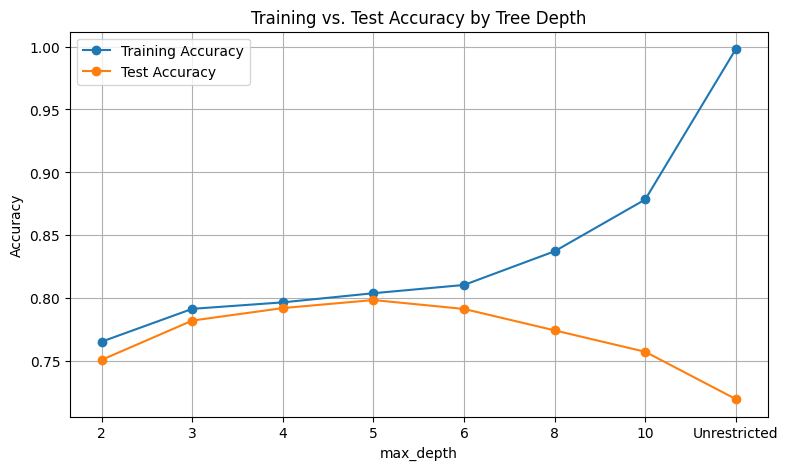

In [ ]:
import matplotlib.pyplot as plt

depth_labels = results_df["max_depth"].astype(str)

plt.figure(figsize=(9, 5))

plt.plot(
    depth_labels,
    results_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_labels,
    results_df["Test Accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Training vs. Test Accuracy by Tree Depth")
plt.legend()
plt.grid(True)

plt.show()

### Interpretation

The plot shows that training accuracy continues to increase as the tree becomes deeper, while test accuracy increases only up to depth 5 and then starts to decrease. Overfitting begins to appear after approximately depth 5 because the model continues to fit the training data more closely while its performance on unseen test data declines. The unrestricted tree shows the clearest overfitting, with 99.80% training accuracy but only 71.97% test accuracy.

# Part 7 — Model Selection, Feature Importance & Interpretation

The Decision Tree depth that best balances training and test performance is selected based on the results from Part 6. The selected model is then evaluated and its feature importance is examined.

## Task 16 — Selecting the Best max_depth

Based on the results from Part 6, max_depth = 5 is selected because it achieved the highest test accuracy of 79.84%. It also provides a better balance between training and test performance than deeper trees, which showed increasing signs of overfitting.

## Task 17 — Evaluation of the Selected Decision Tree

A new Decision Tree is trained using the selected max_depth of 5. Its accuracy, precision, recall, F1-score, and confusion matrix are reported for comparison with the baseline model.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

selected_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

selected_model.fit(X_train, y_train)

y_selected_pred = selected_model.predict(X_test)

selected_accuracy = accuracy_score(y_test, y_selected_pred)
selected_precision = precision_score(y_test, y_selected_pred)
selected_recall = recall_score(y_test, y_selected_pred)
selected_f1 = f1_score(y_test, y_selected_pred)
selected_cm = confusion_matrix(y_test, y_selected_pred)

print("Accuracy:", selected_accuracy)
print("Precision:", selected_precision)
print("Recall:", selected_recall)
print("F1-score:", selected_f1)
print("\nConfusion Matrix:")
print(selected_cm)

Accuracy: 0.7984386089425124
Precision: 0.6347305389221557
Recall: 0.5668449197860963
F1-score: 0.5988700564971752

Confusion Matrix:
[[913 122]
 [162 212]]


### Interpretation

The selected Decision Tree provides a more balanced performance on unseen test data than the unrestricted baseline tree. Limiting the tree depth reduces overfitting and improves the model's ability to generalize to the test set.

## Task 18 — Decision Tree Using Entropy

A Decision Tree is trained using `entropy` as the splitting criterion while keeping the selected max_depth of 5. Its evaluation metrics are compared with the baseline model.

In [ ]:
entropy_model = DecisionTreeClassifier(
    max_depth=5,
    criterion="entropy",
    random_state=42
)

entropy_model.fit(X_train, y_train)

y_entropy_pred = entropy_model.predict(X_test)

entropy_accuracy = accuracy_score(y_test, y_entropy_pred)
entropy_precision = precision_score(y_test, y_entropy_pred)
entropy_recall = recall_score(y_test, y_entropy_pred)
entropy_f1 = f1_score(y_test, y_entropy_pred)
entropy_cm = confusion_matrix(y_test, y_entropy_pred)

print("Accuracy:", entropy_accuracy)
print("Precision:", entropy_precision)
print("Recall:", entropy_recall)
print("F1-score:", entropy_f1)
print("\nConfusion Matrix:")
print(entropy_cm)

Accuracy: 0.7970191625266146
Precision: 0.6309523809523809
Recall: 0.5668449197860963
F1-score: 0.5971830985915493

Confusion Matrix:
[[911 124]
 [162 212]]


### Interpretation

The entropy-based Decision Tree is compared with the baseline Gini-based tree using the same maximum depth. The differences in accuracy, precision, recall, and F1-score show how the choice of splitting criterion affects classification performance.

## Task 19 — Feature Importance

The feature importance values of the selected Decision Tree are extracted and visualized. The most important features are identified based on their contribution to the model's decisions.

Top 5 Features:
Contract_Month-to-month        0.513973
InternetService_Fiber optic    0.163262
tenure                         0.156717
TotalCharges                   0.036499
MonthlyCharges                 0.035922
dtype: float64


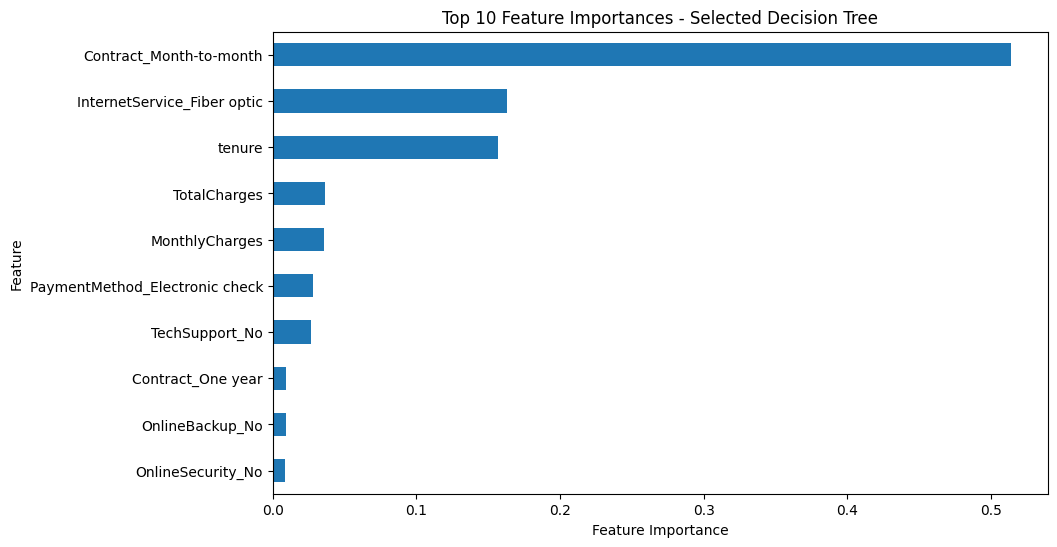

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importances = selected_model.feature_importances_

feature_importance = pd.Series(
    importances,
    index=X.columns
).sort_values(ascending=False)

print("Top 5 Features:")
print(feature_importance.head(5))

plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Selected Decision Tree")

plt.show()

### Interpretation

The feature importance results show that Contract_Month-to-month is the most important feature, with an importance of about 0.514. InternetService_Fiber optic and tenure are the next most important features, with importance values of about 0.164 and 0.157 respectively. This shows that contract type, internet service, and customer tenure contributed most to the Decision Tree's predictions.

## Task 20 — Connecting Feature Importance with EDA

The most important features identified by the Decision Tree are compared with the patterns observed during the EDA in Lab 2. The comparison helps determine whether the model's learned patterns agree with the relationships observed during exploratory data analysis.

### Interpretation

The top features from the Decision Tree agree with the patterns observed in Lab 2's EDA. Month-to-month contracts and fiber optic internet service showed higher churn rates in the EDA, and both appear among the most important features in the Decision Tree. Tenure was also identified as an important feature, supporting the patterns observed between customer tenure and churn.

## Task 21 — Conclusion

The selected Decision Tree model uses a max_depth of 5 because it provides the best balance between training and test performance. It achieved 79.84% test accuracy, with a precision of 63.47%, recall of 56.68%, and F1-score of 59.88%. The unrestricted baseline tree showed clear overfitting, with 99.80% training accuracy but only 71.97% test accuracy. The main limitation is that the model does not correctly identify all churn customers.

## Task 22 — Next Steps

If more time were available, I would try a different classification algorithm and perform additional feature engineering to improve the model's performance. I would also explore techniques for handling class imbalance, such as class weighting or resampling. These approaches could help improve the identification of customers who are likely to churn.

## Task 23 — ID3 from Scratch

The ID3 decision tree algorithm is implemented from scratch using the Play Badminton dataset. Entropy and information gain are calculated manually without using any built-in decision tree libraries. The information gain values for each attribute are printed at every split.

In [ ]:
import pandas as pd
import math

# Play Badminton dataset
data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rainy", "Rainy", "Rainy",
        "Overcast", "Sunny", "Sunny", "Rainy", "Sunny", "Overcast",
        "Overcast", "Rainy"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild", "Cool", "Cool",
        "Cool", "Mild", "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High", "Normal", "Normal",
        "Normal", "High", "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],
    "Windy": [
        "Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],
    "PlayTennis": [
        "No", "No", "Yes", "Yes", "Yes", "No",
        "Yes", "No", "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}

df = pd.DataFrame(data)


# Entropy function
def entropy(target):
    values = target.value_counts()
    total = len(target)

    entropy_value = 0

    for count in values:
        probability = count / total
        entropy_value -= probability * math.log2(probability)

    return entropy_value


# Information Gain function
def information_gain(data, attribute, target="PlayTennis"):
    total_entropy = entropy(data[target])

    weighted_entropy = 0

    for value in data[attribute].unique():
        subset = data[data[attribute] == value]
        weight = len(subset) / len(data)
        weighted_entropy += weight * entropy(subset[target])

    return total_entropy - weighted_entropy


# ID3 algorithm
def id3(data, attributes, target="PlayTennis", level=0):

    # Stop if all target values are the same
    if len(data[target].unique()) == 1:
        return data[target].iloc[0]

    # Stop if no attributes remain
    if len(attributes) == 0:
        return data[target].mode()[0]

    print("\n" + "=" * 50)
    print("Split Level:", level)

    # Calculate gain for every remaining attribute
    gains = {}

    for attribute in attributes:
        gains[attribute] = information_gain(data, attribute, target)
        print(attribute, "Gain =", round(gains[attribute], 4))

    # Select attribute with highest information gain
    best_attribute = max(gains, key=gains.get)

    print("Best Attribute:", best_attribute)

    # Create tree branches
    tree = {best_attribute: {}}

    remaining_attributes = [
        attribute for attribute in attributes
        if attribute != best_attribute
    ]

    for value in data[best_attribute].unique():

        subset = data[data[best_attribute] == value]

        if len(subset) == 0:
            tree[best_attribute][value] = data[target].mode()[0]

        else:
            tree[best_attribute][value] = id3(
                subset,
                remaining_attributes,
                target,
                level + 1
            )

    return tree


# Build the ID3 tree
attributes = ["Outlook", "Temperature", "Humidity", "Windy"]

tree = id3(df, attributes)

print("\nFinal ID3 Decision Tree:")
print(tree)


Split Level: 0
Outlook Gain = 0.2467
Temperature Gain = 0.0292
Humidity Gain = 0.1518
Windy Gain = 0.0481
Best Attribute: Outlook

Split Level: 1
Temperature Gain = 0.571
Humidity Gain = 0.971
Windy Gain = 0.02
Best Attribute: Humidity

Split Level: 1
Temperature Gain = 0.02
Humidity Gain = 0.02
Windy Gain = 0.971
Best Attribute: Windy

Final ID3 Decision Tree:
{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rainy': {'Windy': {'Weak': 'Yes', 'Strong': 'No'}}}}


### Interpretation

The ID3 algorithm selected Outlook as the root attribute because it had the highest information gain of 0.2467. For the Sunny branch, Humidity had the highest information gain of 0.971, while for the Rainy branch, Windy had the highest information gain of 0.971. The Overcast branch directly results in Yes because all Overcast examples in the dataset have the same target value.